# Stage 2: LLM Factor Mining and Feature Selection

## Step 1: Shared Data, Models and Time Partitions

In [1]:
from pathlib import Path
from io import BytesIO
import os,sys,json,inspect,importlib.util,warnings,textwrap
for variable in ('OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS'):
    os.environ.setdefault(variable,'1')
warnings.filterwarnings('ignore',message="'penalty' was deprecated.*",category=FutureWarning)
warnings.filterwarnings('ignore',message='Inconsistent values: penalty=.*',category=UserWarning)
ROOT=Path.cwd()
while not (ROOT/'src').is_dir() and ROOT.parent!=ROOT:ROOT=ROOT.parent
assert (ROOT/'src').is_dir(), 'Extract the complete project before running.'
FACTOR=ROOT/'Factor_Selection_80';OUT=FACTOR/'Regeneration_Study'
PRESENTATION=FACTOR/'Presentation_Complete';PRESENTATION.mkdir(exist_ok=True)
for path in [ROOT,FACTOR,FACTOR/'Temporal_Study',FACTOR/'Cap_Control',OUT]:sys.path.insert(0,str(path))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display as notebook_display,Image,HTML
from threadpoolctl import threadpool_limits
_threads=threadpool_limits(limits=1)
import select_and_evaluate as selection
import regenerate_pool as mining
import final_report as report
import audit_delivery
MODEL_NAMES={'LR':'Logistic Regression','RF':'Random Forest'}
METHOD_NAMES={'single_reference':'Single-factor ranking','MI_filter':'Mutual information',
    'L1_stability':'L1 selection','RF_importance':'Random Forest importance',
    'inner_forward_LR':'Forward combination search'}
pd.set_option('display.max_columns',None)
pd.set_option('display.max_colwidth',None)
TABLE_LABELS={'Mean individual development gain':'Mean AUC change',
    'round':'Round','name':'Factor','formula':'Full formula',
    'mean_gain_vs_baseline':'AUC change alone','mean_conditional_Q3_gain':'AUC change in probe',
    'reason':'Reason','duplicate_of':'Same information as','Rows':'Days',
    'First signal':'First input day','Last signal':'Last input day','Last target':'Last answer day',
    'Development AUC':'Q3 AUC','step':'Added so far','factor':'Factor',
    'mean_inner_auc':'Training-fold AUC','gain':'AUC change',
    'fraction_folds_improved':'Share of checks improved'}
def display(*objects,**kwargs):
    for value in objects:
        if not isinstance(value,pd.DataFrame):
            notebook_display(value,**kwargs)
            continue
        frame=value.rename(columns=TABLE_LABELS)
        table=frame.to_html(index=frame.index.name is not None,border=0,
            max_rows=None,max_cols=None,na_rep='Not scored',
            float_format=lambda number:f'{number:.5f}')
        style='<style>.research-table table{width:100%;table-layout:fixed;border-collapse:collapse;font:14px/1.5 sans-serif}.research-table th,.research-table td{text-align:left!important;vertical-align:top;padding:8px;border-bottom:1px solid #dce1e7;white-space:normal!important;overflow-wrap:anywhere;word-break:normal}.research-table thead{background:#edf2f6}.research-table tbody tr:nth-child(even){background:#f8fafb}</style>'
        notebook_display(HTML(style+'<div class="research-table">'+table+'</div>'))

plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
def show_figure(fig,name):
    fig.tight_layout();fig.savefig(PRESENTATION/name,dpi=160,bbox_inches='tight')
    buffer=BytesIO();fig.savefig(buffer,format='png',dpi=160,bbox_inches='tight')
    display(Image(data=buffer.getvalue()));plt.close(fig)
plan,candidates=selection.verify_pool()
state=mining.read(OUT/'api_run/state.json')
prices,features=mining.early_data()
display(pd.DataFrame([
    {'Item':'Market inputs','Setting':'Apple (AAPL), QQQ, Microsoft (MSFT), NVIDIA (NVDA)'},
    {'Item':'Prediction target','Setting':'Apple next trading-day close: up (1) or not up (0)'},
    {'Item':'Original factors','Setting':str(len(selection.ex.BASE))},
    {'Item':'Logistic Regression','Setting':'StandardScaler; C=1; max_iter=2000; seed42'},
    {'Item':'Random Forest','Setting':'300 trees; depth5; minleaf5; balanced; seeds0/1/2'},
    {'Item':'Factor/method development','Setting':'2022-2024 Q3'},
    {'Item':'Primary historical evaluation','Setting':'2025 Q4'}]))

print('The model settings above are fixed training choices, not performance scores or pass thresholds.')


Item,Setting
Market inputs,"Apple (AAPL), QQQ, Microsoft (MSFT), NVIDIA (NVDA)"
Prediction target,Apple next trading-day close: up (1) or not up (0)
Original factors,22
Logistic Regression,StandardScaler; C=1; max_iter=2000; seed42
Random Forest,300 trees; depth5; minleaf5; balanced; seeds0/1/2
Factor/method development,2022-2024 Q3
Primary historical evaluation,2025 Q4


The model settings above are fixed training choices, not performance scores or pass thresholds.


In [2]:
split_rows=[]
development_splits=mining.development_splits(features,prices,[])
for year,(training,validation) in development_splits.items():
    assert training.target_date.max()<validation.Date.min()
    for label,frame in [('Training Q1-Q2',training),('Development Q3',validation)]:
        split_rows.append({'Year':year,'Partition':label,'Rows':len(frame),
            'First signal':str(frame.Date.min().date()),'Last signal':str(frame.Date.max().date()),
            'Last target':str(frame.target_date.max().date())})
raw=pd.read_csv(selection.ex.SOURCE,parse_dates=['Date'])
full_data=selection.shared.frame_through(raw,candidates,'2025-12-31')
for quarters,label in [([1,2],'Training Q1-Q2'),([4],'Evaluation Q4')]:
    frame=selection.shared.contained_partition(full_data,2025,quarters)
    split_rows.append({'Year':2025,'Partition':label,'Rows':len(frame),
        'First signal':str(frame.Date.min().date()),'Last signal':str(frame.Date.max().date()),
        'Last target':str(frame.target_date.max().date())})
display(pd.DataFrame(split_rows))
print('Time and next-day target boundaries verified.')


Year,Partition,Days,First input day,Last input day,Last answer day
2022,Training Q1-Q2,123,2022-01-03,2022-06-29,2022-06-30
2022,Development Q3,63,2022-07-01,2022-09-29,2022-09-30
2023,Training Q1-Q2,123,2023-01-03,2023-06-29,2023-06-30
2023,Development Q3,62,2023-07-03,2023-09-28,2023-09-29
2024,Training Q1-Q2,123,2024-01-02,2024-06-27,2024-06-28
2024,Development Q3,63,2024-07-01,2024-09-27,2024-09-30
2025,Training Q1-Q2,121,2025-01-02,2025-06-27,2025-06-30
2025,Evaluation Q4,63,2025-10-01,2025-12-30,2025-12-31


Time and next-day target boundaries verified.


## Step 2: Actual LLM Generation, Scoring and Full Feedback

The completed API loop produced 80 valid factors from 91 proposals, retaining all 11 invalid proposals and their reasons. Validity means a formula is computable; predictive usefulness is assessed separately. Every later prompt includes all previous factor successes and failures.

This section verifies the saved live responses and displays the actual feedback. The original generation implementation and raw requests/responses are included in the project; no new API request is sent during this presentation.

In [3]:
assert len(candidates)==80 and state['genuine_live_api_run']
print('Actual LLM:',state['receipts'][0]['model'])
round_rows=[];history=[]
for folder in sorted((OUT/'api_run').glob('round_*')):
    raw_response=mining.read(folder/'request_response.json')
    number=int(folder.name.split('_')[-1])
    records=[r for r in state['records'] if r.get('round')==number]
    valid=[r for r in records if r.get('status')=='valid']
    round_rows.append({'Round':number,'Response':raw_response['status'],
        'Valid':len(valid),'Invalid':sum(r.get('status')=='invalid' for r in records),
        'Mean individual development gain':np.mean([r['mean_gain_vs_baseline'] for r in valid]) if valid else np.nan})
    if (folder/'parsed_response.json').exists():
        reply=mining.api.parse_response(raw_response)
        assert reply==mining.read(folder/'parsed_response.json')
        request=mining.read(folder/'request.json')
        assert request['input']==(folder/'prompt.txt').read_text()
        assert json.dumps(history,ensure_ascii=False,allow_nan=False) in request['input']
        history=mining.read(folder/'feedback_after_scoring.json')['history']
assert history==state['records']
display(pd.DataFrame(round_rows).round(5))
print('All previous factor outcomes were verified in every later successful prompt.')


Actual LLM: gpt-6-luna


Round,Response,Valid,Invalid,Mean AUC change
1,completed,10,2,0.00028
2,completed,12,0,-0.00046
3,completed,9,3,-0.00699
4,incomplete,0,0,Not scored
5,completed,12,0,0.00100
6,completed,10,2,0.00084
7,completed,11,1,-0.00443
8,completed,10,2,-0.00292
9,completed,5,1,0.00494
10,completed,1,0,0.02231


All previous factor outcomes were verified in every later successful prompt.


In [4]:
records=pd.DataFrame(state['records'])
catalogue=pd.DataFrame(candidates)
print('Example valid proposals and their automatically computed development scores:')
display(records.loc[records.status.eq('valid'),
    ['round','name','formula','mean_gain_vs_baseline','mean_conditional_Q3_gain']].head(5).round(5))
print('Example rejected formulas; all 11 reasons remain in the full records:')
display(records.loc[records.status.eq('invalid'),['round','name','reason']].head(3))
print('Actual model reflection before round 2:')
reflection=mining.read(OUT/'api_run/round_02/parsed_response.json')['reflection']
print(textwrap.fill(reflection,width=105))


Example valid proposals and their automatically computed development scores:


Round,Factor,Full formula,AUC change alone,AUC change in probe
1,r2_downside_share_5d,"safe_divide(subtract(rolling_sum(abs(pct_change(AAPL_Close, 1)), 5), rolling_sum(pct_change(AAPL_Close, 1), 5)), rolling_sum(abs(pct_change(AAPL_Close, 1)), 5))",-0.01044,-0.01044
1,r2_worst_day_return_share_10d,"safe_divide(abs(rolling_min(pct_change(AAPL_Close, 1), 10)), rolling_sum(abs(pct_change(AAPL_Close, 1)), 10))",-0.00538,-0.00538
1,r2_aapl_peer_return_gap_3d,"subtract(pct_change(AAPL_Close, 3), multiply(add(add(pct_change(QQQ_Close, 3), pct_change(MSFT_Close, 3)), pct_change(NVDA_Close, 3)), 0.3333333333))",0.01037,0.01037
1,r2_peer_return_dispersion_3d,"add(add(abs(subtract(pct_change(QQQ_Close, 3), pct_change(MSFT_Close, 3))), abs(subtract(pct_change(QQQ_Close, 3), pct_change(NVDA_Close, 3)))), abs(subtract(pct_change(MSFT_Close, 3), pct_change(NVDA_Close, 3))))",-0.01530,-0.01530
1,r2_volume_weighted_return_5d,"safe_divide(rolling_sum(multiply(AAPL_Volume, pct_change(AAPL_Close, 1)), 5), rolling_sum(AAPL_Volume, 5))",0.00143,0.00143


Example rejected formulas; all 11 reasons remain in the full records:


Round,Factor,Reason
1,r2_peer_direction_breadth_gap,nested deeper than 6
1,r2_volume_weighted_downside_share_5d,nested deeper than 6
3,r2_downside_squared_return_share_10d,nested deeper than 6


Actual model reflection before round 2:
Round 1 candidates were generally weak alone: most mean Q3 AUCs were near 0.5, and the downside-share and
volume-activity measures added little in their probes. The three-year pattern is uneven: the prior
provisional combination scored above the baseline in 2022 and 2023 but below it in 2024, so its
conditional result is not consistent across years. The three-day AAPL-versus-peers return gap and the
overnight-gap/range and adjacent-sign-persistence ideas showed some Q3 signal, but their annual results
also vary. I therefore avoid treating any result as robust, include more range, regime, and liquidity
constructions, and avoid simply repeating the prior return-gap and volume-weighted-return formulas. The
previous invalid proposals also show why formula depth needs checking; all candidates below use shallow
permitted expressions. These are testable hypotheses, not claims of profitability.


## Step 3: Automatic Factor Implementation and Calculation

All 80 formulas were calculated as daily columns. The generated Python implementations were checked against the shared formula interpreter and against changed future inputs. The training-only quality screen removed two numerical duplicates, leaving 78 eligible candidates for compact selection; all 80 remain in the full-pool control.

The example below measures the previous session's candle-body size divided by its high-low range. It is present in both final selected sets. Its proposed interpretation is a hypothesis tested by the model.

In [5]:
all_prices=selection.wide_prices(raw)
factor_values=selection.ex.calculate(candidates,all_prices)
selection.exporter.verify_export(candidates,(OUT/'generated_factor_functions.py').read_text(),all_prices)
assert factor_values.shape[1]==80
quality=pd.read_csv(OUT/'quality_gate.csv')
eligible=sorted(quality.loc[quality.eligible,'name'].tolist())
assert len(eligible)==78
print(f'Calculated {len(factor_values)} dates and 80 candidate columns; all 80 implementation and future-input checks passed.')
display(quality.loc[~quality.eligible,['name','reason','duplicate_of']])
display(factor_values.loc['2025-01-02':'2025-01-07',
    ['r2_prior_body_share_of_range','r2_prior_close_range_position','r2_aapl_relative_volume_vs_msft']].round(5))


Calculated 1253 dates and 80 candidate columns; all 80 implementation and future-input checks passed.


Factor,Reason,Same information as
r2_downside_share_5d,affine_candidate_duplicate_on_training,r2_signed_return_reversal_balance_5d
r2_prior_wick_balance,affine_candidate_duplicate_on_training,r2_prior_close_range_position


,r2_prior_body_share_of_range,r2_prior_close_range_position,r2_aapl_relative_volume_vs_msft
Date,,,
2025-01-02,0.52468,0.25714,0.23859
2025-01-03,0.69780,0.27885,-0.04954
2025-01-06,0.00000,0.64192,-0.13617
2025-01-07,0.16707,0.43584,-0.15288


In [6]:
spec=importlib.util.spec_from_file_location('complete_factor_functions',OUT/'generated_factor_functions.py')
functions=importlib.util.module_from_spec(spec);spec.loader.exec_module(functions)
example_name='r2_prior_body_share_of_range'
print(inspect.getsource(functions.FACTOR_FUNCTIONS[example_name]))
date=pd.Timestamp('2024-06-14');previous=all_prices.iloc[all_prices.index.get_loc(date)-1]
manual=abs(previous.AAPL_Close-previous.AAPL_Open)/(previous.AAPL_High-previous.AAPL_Low)
automatic=float(factor_values.loc[date,example_name])
assert np.isclose(manual,automatic)
display(pd.DataFrame([{'Signal date':str(date.date()),'Previous open':previous.AAPL_Open,
    'Previous close':previous.AAPL_Close,'Previous high':previous.AAPL_High,
    'Previous low':previous.AAPL_Low,'Manual value':manual,'Generated value':automatic}]).round(6))
print(catalogue.set_index('name').loc[example_name,'hypothesis'])


def r2_prior_body_share_of_range(prices):
    "A larger absolute prior-session candle body as a share of its range, indicating less intraday wick reversal, is associated with AAPL's next-day close direction."
    result = _safe_divide((((prices['AAPL_Close'].astype(float)).shift(1) - (prices['AAPL_Open'].astype(float)).shift(1))).abs(), ((prices['AAPL_High'].astype(float)).shift(1) - (prices['AAPL_Low'].astype(float)).shift(1)))
    return result.replace([np.inf, -np.inf], np.nan)



Signal date,Previous open,Previous close,Previous high,Previous low,Manual value,Generated value
2024-06-14,212.71237,212.21709,214.70338,209.60201,0.09709,0.09709


A larger absolute prior-session candle body as a share of its range, indicating less intraday wick reversal, is associated with AAPL's next-day close direction.


In [7]:
def score_one_candidate(candidate):
    splits=mining.development_splits(features,prices,[candidate])
    baseline=mining.annual_auc(splits,[])
    added=mining.annual_auc(splits,[candidate['name']])
    return pd.DataFrame({'Year':list(splits),'Original 22 AUC':baseline,
        'Original 22 + factor AUC':added,'Gain':added-baseline})
example_candidate=next(c for c in candidates if c['name']==example_name)
individual=score_one_candidate(example_candidate)
saved_gain=float(records.loc[records.name.eq(example_name)&records.status.eq('valid'),'mean_gain_vs_baseline'].iloc[0])
assert np.isclose(individual.Gain.mean(),saved_gain,atol=1e-12)
display(individual.round(5))
print('This executed calculation reproduces the individual score returned to the LLM.')


Year,Original 22 AUC,Original 22 + factor AUC,Gain
2022,0.37576,0.44747,0.07172
2023,0.63761,0.64496,0.00735
2024,0.49674,0.50870,0.01196


This executed calculation reproduces the individual score returned to the LLM.


## Step 4: Feature Selection and Combination Evidence

The completed comparison contains 23 configurations: baseline/all-80 controls, single-factor ranking, mutual information, L1 selection, Random Forest importance and forward combination search. Ranked subset sizes are 4, 8, 16, 32 and 64; L1 and forward search can use the full eligible pool.

Method and size are chosen separately for each model using mean 2022-2024 Q3 AUC. Within 0.002 of the best score, fewer additions are preferred. The final sets were fixed before later evaluation. The method comparison, executed combination search and all selected names are shown below.

Methods in plain words: single-factor ranking orders candidates by the gain from adding one to the original 22; mutual information measures training-data dependence with the answer; L1 uses a jointly trained model that sets some coefficients to zero; Random Forest importance ranks inputs within trained forests; forward search tests each remaining factor together with the current group.

In [8]:
frozen=selection.select()
development=pd.read_csv(OUT/'development_summary.csv')
method_rows=[]
for model in MODEL_NAMES:
    for method,label in METHOD_NAMES.items():
        rows=development.loc[development.model.eq(model)&development.method.eq(method)]
        identifier=selection.choose(rows);winner=rows.loc[rows.config_id.eq(identifier)].iloc[0]
        method_rows.append({'Model':MODEL_NAMES[model],'Method':label,
            'Additions':int(winner.additions),'Development AUC':winner.mean_auc,
            'Final choice':identifier==frozen['choices'][model]['config_id']})
methods=pd.DataFrame(method_rows)
display(methods.round(5))
display(pd.DataFrame([{'Model':MODEL_NAMES[m],'Chosen method':METHOD_NAMES[c['method']],
    'Added factors':len(c['names']),'Total inputs':len(selection.ex.BASE)+len(c['names'])}
    for m,c in frozen['choices'].items()]))


Model,Method,Additions,Q3 AUC,Final choice
Logistic Regression,Single-factor ranking,16,0.61455,True
Logistic Regression,Mutual information,16,0.50295,False
Logistic Regression,L1 selection,17,0.57979,False
Logistic Regression,Random Forest importance,16,0.52481,False
Logistic Regression,Forward combination search,8,0.49247,False
Random Forest,Single-factor ranking,32,0.53905,False
Random Forest,Mutual information,64,0.52321,False
Random Forest,L1 selection,43,0.53995,False
Random Forest,Random Forest importance,16,0.55559,True
Random Forest,Forward combination search,8,0.52956,False


Model,Chosen method,Added factors,Total inputs
Logistic Regression,Single-factor ranking,16,38
Random Forest,Random Forest importance,16,38


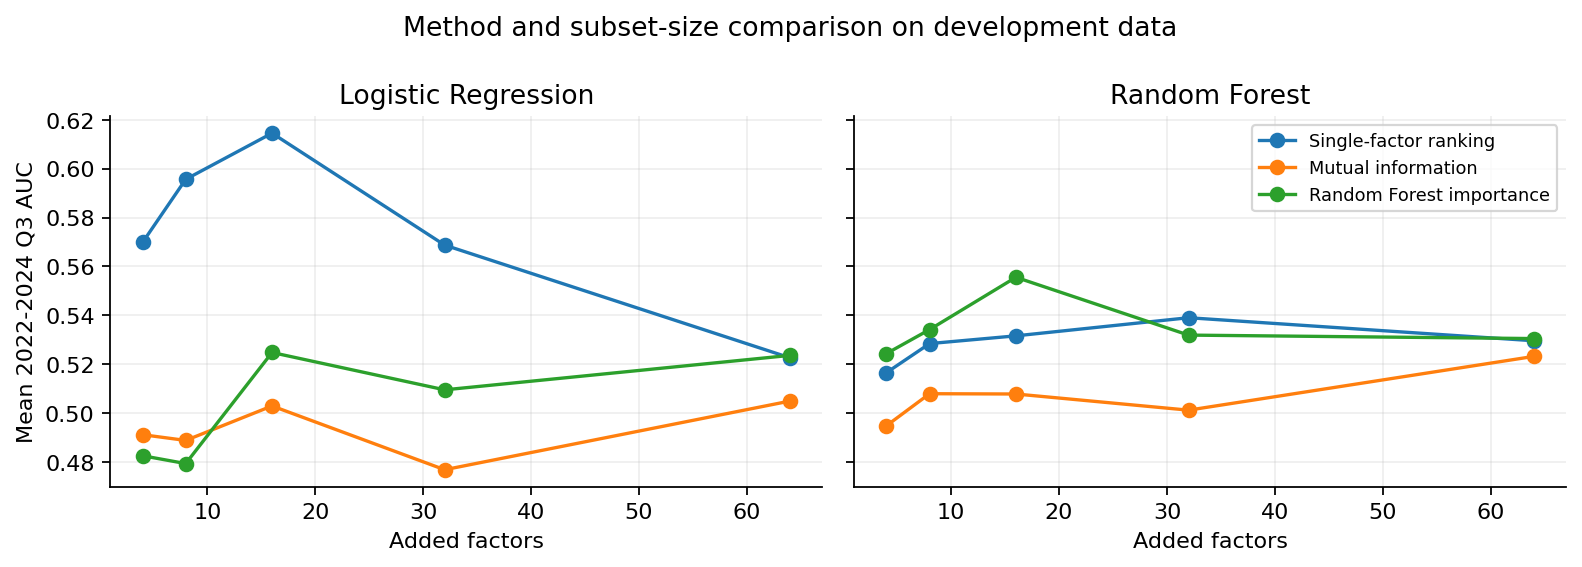

In [9]:
fig,axes=plt.subplots(1,2,figsize=(10,3.6),sharey=True)
for ax,model in zip(axes,MODEL_NAMES):
    for method in ['single_reference','MI_filter','RF_importance']:
        points=development.loc[development.model.eq(model)&development.method.eq(method)].sort_values('additions')
        ax.plot(points.additions,points.mean_auc,'o-',label=METHOD_NAMES[method])
    ax.set_title(MODEL_NAMES[model]);ax.set_xlabel('Added factors');ax.grid(alpha=.2)
axes[0].set_ylabel('Mean 2022-2024 Q3 AUC');axes[1].legend(fontsize=8)
fig.suptitle('Method and subset-size comparison on development data')
show_figure(fig,'development_subset_sizes.png')


**Combination search:** each trial fits a candidate with the current group, using nine chronological folds inside the training periods. Preprocessing is fitted within each fold. An addition must improve mean AUC by at least 0.002 and help at least half the folds. The code below executes this search and verifies its complete path against the recorded experiment.

**Read the search:** there are nine time-ordered training checks. A new addition must increase mean AUC by at least 0.002 and help at least five of those nine checks. A value of 0.55556 in the share column means 5/9 checks improved. The search stopped naturally at eight additions; this is one comparison method, not the final 16-factor choice.


In [10]:
def forward_combination_search(folds,names,minimum_gain=.002,minimum_fraction=.5):
    selected=[];remaining=sorted(names)
    current=selection.fold_scores(folds,[])
    trace=[{'step':0,'factor':'BASELINE','mean_inner_auc':float(current.mean()),
        'gain':0.0,'fraction_folds_improved':0.0}]
    trials=[]
    for step in range(1,len(names)+1):
        options=[]
        for name in remaining:
            scores=selection.fold_scores(folds,selected+[name])
            gains=scores-current;fraction=float((gains>1e-12).mean())
            allowed=bool(gains.mean()>=minimum_gain and fraction>=minimum_fraction)
            trials.append({'step':step,'factor':name,'mean_inner_auc':float(scores.mean()),
                'gain':float(gains.mean()),'fraction_folds_improved':fraction,'passes_step_rule':allowed})
            if allowed:options.append((float(scores.mean()),name,scores,fraction))
        if not options:break
        mean,name,scores,fraction=sorted(options,key=lambda x:(-x[0],x[1]))[0]
        gain=mean-float(current.mean())
        selected.append(name);remaining.remove(name);current=scores
        trace.append({'step':step,'factor':name,'mean_inner_auc':mean,'gain':gain,
            'fraction_folds_improved':fraction})
        print(f'Added {step}: {name}; mean inner AUC={mean:.5f}; gain={gain:+.5f}')
    return selected,pd.DataFrame(trace),pd.DataFrame(trials)


Added 1: r2_peer_relative_volume_nvidia; mean inner AUC=0.56275; gain=+0.02923


Added 2: r2_today_vs_prior_return_magnitude; mean inner AUC=0.58907; gain=+0.02631


Added 3: r2_peer_trend_regime_body; mean inner AUC=0.60816; gain=+0.01910


Added 4: r2_peer_intraday_range_efficiency_gap; mean inner AUC=0.62824; gain=+0.02008


Added 5: r2_nonoverlapping_three_day_return_change; mean inner AUC=0.63361; gain=+0.00536


Added 6: r2_range_per_share_relative_activity; mean inner AUC=0.64418; gain=+0.01057


Added 7: r2_separated_return_sign_agreement; mean inner AUC=0.64864; gain=+0.00445


Added 8: r2_aapl_relative_volume_vs_msft; mean inner AUC=0.66040; gain=+0.01177


Added so far,Factor,Training-fold AUC,AUC change,Share of checks improved
0,BASELINE,0.53352,0.00000,0.00000
1,r2_peer_relative_volume_nvidia,0.56275,0.02923,0.66667
2,r2_today_vs_prior_return_magnitude,0.58907,0.02631,0.55556
3,r2_peer_trend_regime_body,0.60816,0.01910,0.55556
4,r2_peer_intraday_range_efficiency_gap,0.62824,0.02008,0.55556
5,r2_nonoverlapping_three_day_return_change,0.63361,0.00536,0.55556
6,r2_range_per_share_relative_activity,0.64418,0.01057,0.55556
7,r2_separated_return_sign_agreement,0.64864,0.00445,0.55556
8,r2_aapl_relative_volume_vs_msft,0.66040,0.01177,0.55556


Completed 666 candidate/group trials. No next addition passed the fixed rule.


Factor,Gain alone,Gain after earlier factors
r2_peer_intraday_range_efficiency_gap,-0.00420,0.02008
r2_aapl_relative_volume_vs_msft,-0.00725,0.01177


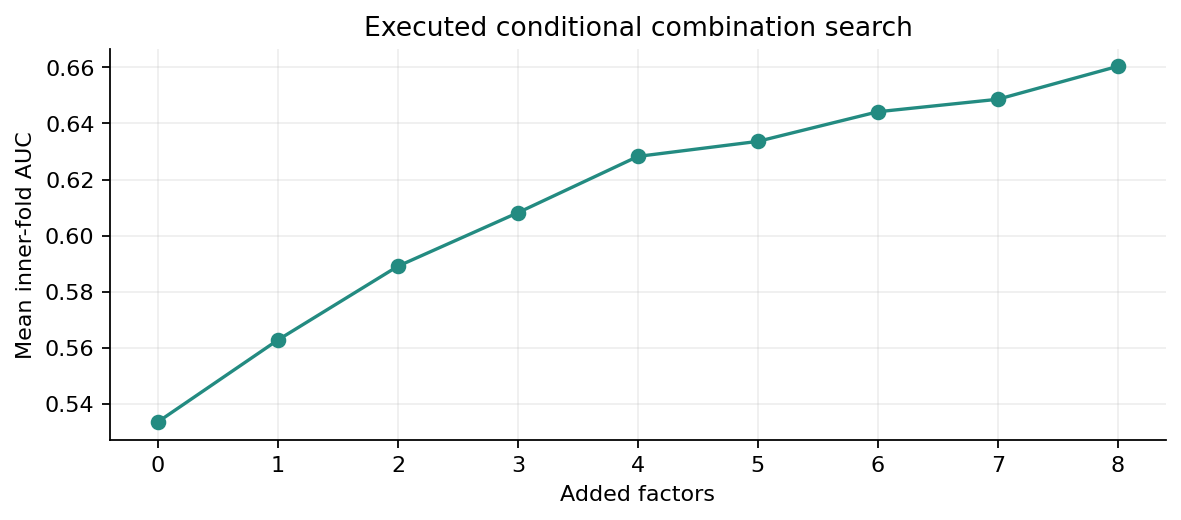

In [11]:
_,early_data,_=selection.early_inputs(candidates)
fold_settings=plan['final_selectors']['inner_time_forward']
folds,boundaries=selection.inner_training_folds(early_data,eligible,fold_settings)
forward_names,trace,trials=forward_combination_search(folds,eligible)
expected_trace=pd.read_csv(OUT/'inner_forward_trace.csv')
pd.testing.assert_frame_equal(trace,expected_trace,check_dtype=False,rtol=1e-11,atol=1e-12)
assert forward_names==frozen['feature_sets']['inner_forward_LR']['names']
expected_trials=pd.read_csv(OUT/'inner_forward_trials.csv')
pd.testing.assert_frame_equal(trials,expected_trials[trials.columns],check_dtype=False,rtol=1e-11,atol=1e-12)
display(trace.round(5))
print(f'Completed {len(trials)} candidate/group trials. No next addition passed the fixed rule.')
display(report.conditional_table().query('weak_alone_positive_together')[
    ['factor','inner_gain_alone','inner_gain_after_previous_factors']].rename(columns={
    'factor':'Factor','inner_gain_alone':'Gain alone','inner_gain_after_previous_factors':'Gain after earlier factors'}).round(5))
fig,ax=plt.subplots(figsize=(7.5,3.4))
ax.plot(trace.step,trace.mean_inner_auc,'o-',color='#238b81');ax.set_xticks(trace.step)
ax.set(xlabel='Added factors',ylabel='Mean inner-fold AUC',title='Executed conditional combination search')
ax.grid(alpha=.2);show_figure(fig,'combination_search.png')


In [12]:
selected_table=pd.DataFrame({MODEL_NAMES[m]:c['names'] for m,c in frozen['choices'].items()})
selected_table.index=np.arange(1,len(selected_table)+1);selected_table.index.name='Rank'
display(selected_table)
print('The final choices are single-factor ranking with 16 additions for Logistic Regression,')
print('and training importance with 16 additions for Random Forest. The sets are different.')
print('Forward search is a compared method and conditional-value example; it is not the final 16-factor policy.')

shared_names=set(frozen['choices']['LR']['names']) & set(frozen['choices']['RF']['names'])
assert len(shared_names)==4
print('Each model has its own selected 16 additions: four names are shared; each list has 12 other names.')
print('Original 22 + all 80 = 102 inputs. Original 22 + a selected 16 = 38 inputs.')


,Logistic Regression,Random Forest
Rank,,
1,r2_intraday_body_vs_overnight_move,r2_volume_weighted_range_position_10d
2,r2_prior_body_share_of_range,r2_peer_relative_volume_nvidia
3,r2_signed_overnight_gap_range_share,r2_relative_dollar_activity_short_long
4,r2_peer_sign_consensus,r2_nonoverlapping_three_day_return_change
5,r2_prior_close_range_position,r2_volume_regime_gap
6,r2_prior_body_signed_range_fraction,r2_prior_close_range_position
7,r2_volume_acceleration_body_5d,r2_prior_range_width_scaled
8,r2_adjacent_return_sign_persistence_3d,r2_prior_close_to_low_scaled
9,r2_close_location_range_change,r2_aapl_peer_return_gap_3d


The final choices are single-factor ranking with 16 additions for Logistic Regression,
and training importance with 16 additions for Random Forest. The sets are different.
Forward search is a compared method and conditional-value example; it is not the final 16-factor policy.
Each model has its own selected 16 additions: four names are shared; each list has 12 other names.
Original 22 + all 80 = 102 inputs. Original 22 + a selected 16 = 38 inputs.


## Step 5: Fixed Historical Results and Completed Verification

The fixed subsets are compared with the original 22 inputs and with all 80 additions on the same 63 dated 2025 Q4 targets. AUC is primary; balanced accuracy is also reported. Nothing was reselected from these evaluation scores.

AUC 0.5 means chance-level ranking, 1 means perfect ranking, and below 0.5 means worse-than-chance ranking in that period. Balanced accuracy averages the fraction of up days called correctly and the fraction of not-up days called correctly. To make those daily calls, the model uses probability >= 0.5 for up. That daily probability threshold is different from an AUC score of 0.5.

The uncertainty table shows the selected-minus-original AUC difference and a conditional 95% interval. An interval spanning zero does not establish a reliable gain. The final PASS rows verify implementation and reproducibility; they do not establish profitable trading or reliable future prediction.


In [13]:
selection.evaluate()
all_results=report.primary_table()
primary=all_results.loc[all_results.evaluation.eq('2025_Q4_primary')&~all_results.feature_set.eq('Previous 80')].copy()
SET_NAMES={'Baseline (22)':'Original 22','All new 80':'Original 22 + all 80',
    'Early-Q3 selected policy':'Original 22 + selected 16'}
table=primary[['model','feature_set','additions','rows','AUC','balanced_accuracy']].copy()
table['model']=table.model.map(MODEL_NAMES);table['feature_set']=table.feature_set.map(SET_NAMES)
display(table.rename(columns={'model':'Model','feature_set':'Inputs','additions':'Additions',
    'rows':'Test rows','balanced_accuracy':'Balanced accuracy'}).round(5))


Model,Inputs,Additions,Test rows,AUC,Balanced accuracy
Logistic Regression,Original 22,0,63,0.47755,0.41071
Logistic Regression,Original 22 + all 80,80,63,0.48367,0.49643
Logistic Regression,Original 22 + selected 16,16,63,0.53980,0.48929
Random Forest,Original 22,0,63,0.49592,0.41786
Random Forest,Original 22 + all 80,80,63,0.44592,0.43214
Random Forest,Original 22 + selected 16,16,63,0.47959,0.50000


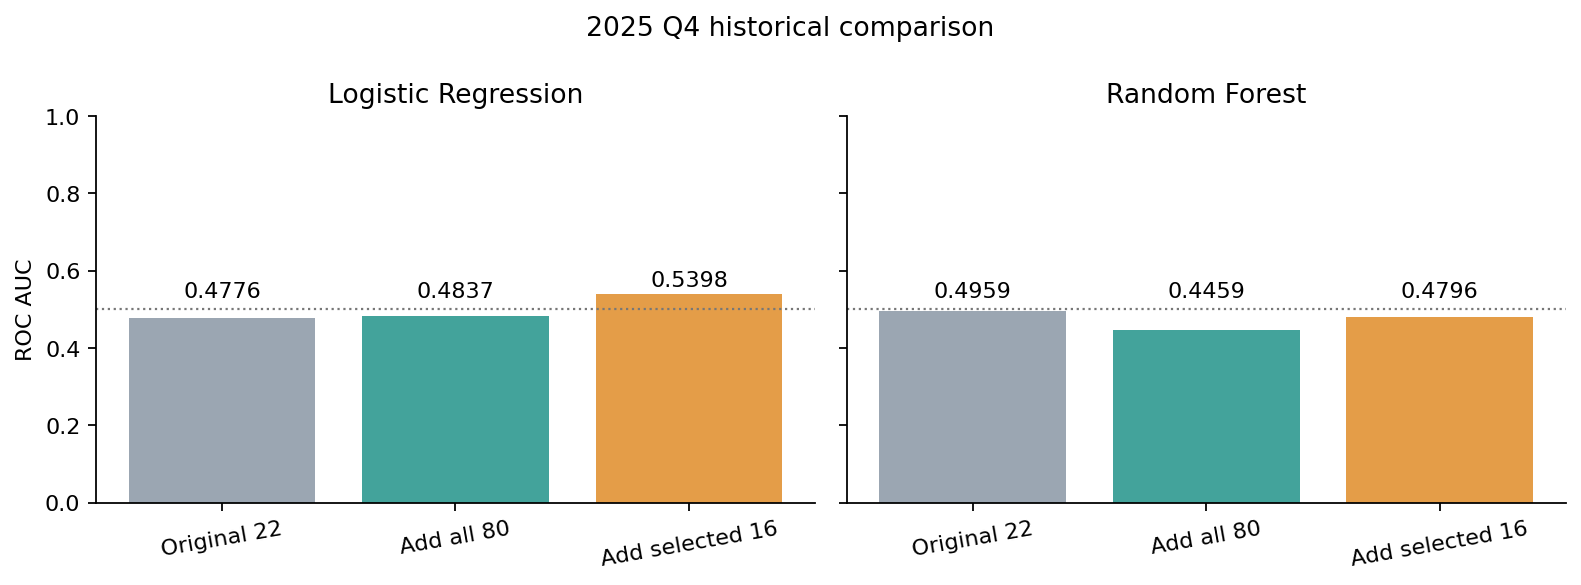

In [14]:
fig,axes=plt.subplots(1,2,figsize=(10,3.7),sharey=True)
for ax,model in zip(axes,MODEL_NAMES):
    frame=primary.loc[primary.model.eq(model)]
    bars=ax.bar(range(3),frame.AUC,color=['#9ba6b2','#43a39b','#e49d48'])
    ax.set_xticks(range(3),['Original 22','Add all 80','Add selected 16'],rotation=10)
    ax.set_title(MODEL_NAMES[model]);ax.set_ylim(0,1);ax.axhline(.5,color='#777',ls=':',lw=1)
    for bar,value in zip(bars,frame.AUC):
        ax.text(bar.get_x()+bar.get_width()/2,max(value+.02,.53),f'{value:.4f}',ha='center')
axes[0].set_ylabel('ROC AUC');fig.suptitle('2025 Q4 historical comparison')
show_figure(fig,'historical_results.png')


In [15]:
uncertainty=pd.read_csv(OUT/'conditional_uncertainty.csv')
intervals=uncertainty.loc[uncertainty.scope.eq('New pool: 2025 Q4 policy')&uncertainty.reference.eq('baseline_22'),
    ['model','AUC_difference','conditional_95pct_low','conditional_95pct_high','includes_zero']].copy()
intervals['model']=intervals.model.map(MODEL_NAMES)
display(intervals.rename(columns={'model':'Model','AUC_difference':'Gain vs original 22',
    'conditional_95pct_low':'Interval low','conditional_95pct_high':'Interval high',
    'includes_zero':'Includes zero'}).round(5))
print('The paired historical intervals include zero. The point gains are not established as reliable future gains.')


Model,Gain vs original 22,Interval low,Interval high,Includes zero
Logistic Regression,0.06224,-0.06466,0.19343,True
Random Forest,-0.01633,-0.16961,0.13684,True


The paired historical intervals include zero. The point gains are not established as reliable future gains.


In [16]:
checks=report.verify();assert checks.passed.all()
delivery=audit_delivery.run();assert delivery['all_passed']
reproduction=mining.read(OUT/'REPRODUCTION_VERIFICATION.json')
assert reproduction['all_passed'] and reproduction['reproduced_choices_identical']
assert all(r['byte_identical'] for r in reproduction['files'])
completed=pd.DataFrame([
    {'Completed check':'All 80 formula implementations and future-input checks','Result':'PASS'},
    {'Completed check':'Time boundaries, model settings and frozen choices','Result':'PASS'},
    {'Completed check':'Executed complete forward path and every candidate/group trial','Result':'PASS'},
    {'Completed check':'610 saved model groups independently checked','Result':'PASS'},
    {'Completed check':'Primary model probabilities reproduced by fresh fits','Result':'PASS'},
    {'Completed check':'Full selection/evaluation recomputed; 9 result files byte-identical','Result':'PASS'}])
display(completed)
completed.to_csv(PRESENTATION/'completed_checks.csv',index=False)
mining.write(PRESENTATION/'COMPLETED.json',{'all_passed':True,'executed_forward_trials':len(trials),
    'formula_candidates':80,'final_additions':{MODEL_NAMES[m]:len(c['names']) for m,c in frozen['choices'].items()},
    'primary_verification_groups':len(checks),'additional_audit_checks':len(delivery['checks']),
    'reproduction_files':len(reproduction['files']),'new_API_calls':0,
    'pool_sha256':frozen['pool_sha256'],'selection_sha256':mining.digest(OUT/'SELECTION_FROZEN.json')})
print('All displayed calculations and verification completed successfully.')


                                                                                                 check  passed                             details
All 80 exported implementations and complete-date factor CSV reproduce through the last available date    True                     1253 daily rows
                         Additional reference/cap Q4 metrics and RF seed means reproduce independently    True                    100 model groups
                         All 80 previous-rule threshold/correlation decisions replay in proposal order    True                                    
               Fresh original shared model functions reproduce the retained factor model-average gains    True 4 years; LR plus all three RF seeds
                                      All delivered code, notebook and documentation source is English    True                           110 files
        Final notebook contains actual counts, four figure outputs, no errors and matching kernel hash    True        

Completed check,Result
All 80 formula implementations and future-input checks,PASS
"Time boundaries, model settings and frozen choices",PASS
Executed complete forward path and every candidate/group trial,PASS
610 saved model groups independently checked,PASS
Primary model probabilities reproduced by fresh fits,PASS
Full selection/evaluation recomputed; 9 result files byte-identical,PASS


All displayed calculations and verification completed successfully.


**Measured conclusion:** selecting 16 additions improved Logistic Regression's 2025 Q4 AUC from 0.4776 to 0.5398, compared with 0.4837 for all 80. Random Forest's selected subset beat all 80 but did not beat its original baseline. Individually weak factors showed conditional usefulness in development.

These historical periods had been inspected earlier; the results are retrospective and the intervals include zero. The complete records and supplementary studies are preserved in the project. Shared team code is attributed; ChatGPT assisted implementation and analysis.
